# Clan matches 

This notebook only checks the match-level file: row quality, clan identifiers, target consistency, side balance, and the point-margin distribution.  



In [5]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("../..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TRAIN_DATA_PATH = PROJECT_ROOT / "data" / "train"
MATCHES_FILE = TRAIN_DATA_PATH / "clan_matches_training.csv"

matches = pd.read_csv(MATCHES_FILE)

print("Matches shape:", matches.shape)
display(matches.sample(5))

Matches shape: (24288, 5)


,clan_1_id,clan_2_id,clan_1_points,clan_2_points,clan_winner
20680,clan_853,clan_47800,66,43,1
20736,clan_5087,clan_22437,68,15,1
2689,clan_40007,clan_44221,24,78,2
7345,clan_30926,clan_35489,37,39,2
22638,clan_38365,clan_40858,75,30,1


## Basic table checks

First pass: missing values, duplicate rows, and a small numeric summary of the two score columns. These checks are mainly here to catch data-loading mistakes before looking at modeling signal.


In [6]:
missing = matches.isna().sum().rename("n_missing")
missing = missing[missing > 0].sort_values(ascending=False)

print("Duplicate full rows:", matches.duplicated().sum())

if len(missing):
    display(missing.to_frame())
else:
    print("No missing values.")

display(matches[["clan_1_points", "clan_2_points"]].describe().T)

Duplicate full rows: 0
No missing values.


,count,mean,std,min,25%,50%,75%,max
clan_1_points,24288.0,47.487566,18.707603,0.0,34.0,47.0,60.0,144.0
clan_2_points,24288.0,47.515316,18.584584,0.0,35.0,47.0,60.0,138.0


## Clan identifiers

If clans repeated across matches, historical strength features would be possible. 


In [7]:
clan_mentions = pd.concat(
    [
        matches["clan_1_id"].rename("clan_id"),
        matches["clan_2_id"].rename("clan_id"),
    ],
    ignore_index=True,
)

clan_counts = (
    clan_mentions
    .value_counts()
    .rename_axis("clan_id")
    .reset_index(name="n_mentions")
    .sort_values(["n_mentions", "clan_id"], ascending=[False, True])
    .reset_index(drop=True)
)

summary = pd.Series({
    "n_matches": len(matches),
    "total_clan_mentions": len(clan_mentions),
    "unique_clans": clan_counts["clan_id"].nunique(),
    "clans_appearing_more_than_once": int((clan_counts["n_mentions"] > 1).sum()),
})

display(summary.to_frame("value"))

,value
n_matches,24288
total_clan_mentions,48576
unique_clans,48576
clans_appearing_more_than_once,0


## Target and side balance

The target is stored as `clan_winner`, where 1 means `clan_1` won and 2 means `clan_2` won.  
Two things are checked here:

- whether `clan_winner` matches the point totals;
- whether `clan_1` has a meaningful side advantage.


In [8]:
winner_counts = matches["clan_winner"].value_counts().sort_index()
side_balance = pd.DataFrame({
    "n_matches": winner_counts,
    "share": winner_counts / len(matches),
})

display(side_balance)

,n_matches,share
clan_winner,,
1,12126,0.499259
2,12162,0.500741


In [9]:
winner_from_points = np.select(
    [
        matches["clan_1_points"] > matches["clan_2_points"],
        matches["clan_2_points"] > matches["clan_1_points"],
    ],
    [1, 2],
    default=0,  # only possible if points are tied
)

winner_check = matches[["clan_1_points", "clan_2_points", "clan_winner"]].copy()
winner_check["winner_from_points"] = winner_from_points
winner_check["is_consistent"] = winner_check["clan_winner"] == winner_check["winner_from_points"]


print("Tied point totals:", int((winner_check["winner_from_points"] == 0).sum()))

mismatches = winner_check.loc[~winner_check["is_consistent"]]
if len(mismatches):
    display(mismatches.head(10))
else:
    print("No inconsistencies found.")

Tied point totals: 0
No inconsistencies found.


## Point margins

`point_diff` is kept clan-1-oriented throughout the notebook:

```text
point_diff = clan_1_points - clan_2_points
```

The absolute margin is used only for diagnostics. It should not be used as a model feature, since it is only known after the match.


In [10]:
matches = matches.copy()

matches["point_diff"] = matches["clan_1_points"] - matches["clan_2_points"]
matches["abs_point_diff"] = matches["point_diff"].abs()

margin_summary = matches[["point_diff", "abs_point_diff"]].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

display(margin_summary)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
point_diff,24288.0,-0.027750,36.255850,-138.0,-81.0,-60.0,-47.0,-26.0,-1.0,25.0,47.0,60.0,82.0,144.0
abs_point_diff,24288.0,29.484519,21.097743,1.0,1.0,3.0,6.0,12.0,26.0,42.0,60.0,71.0,90.0,144.0


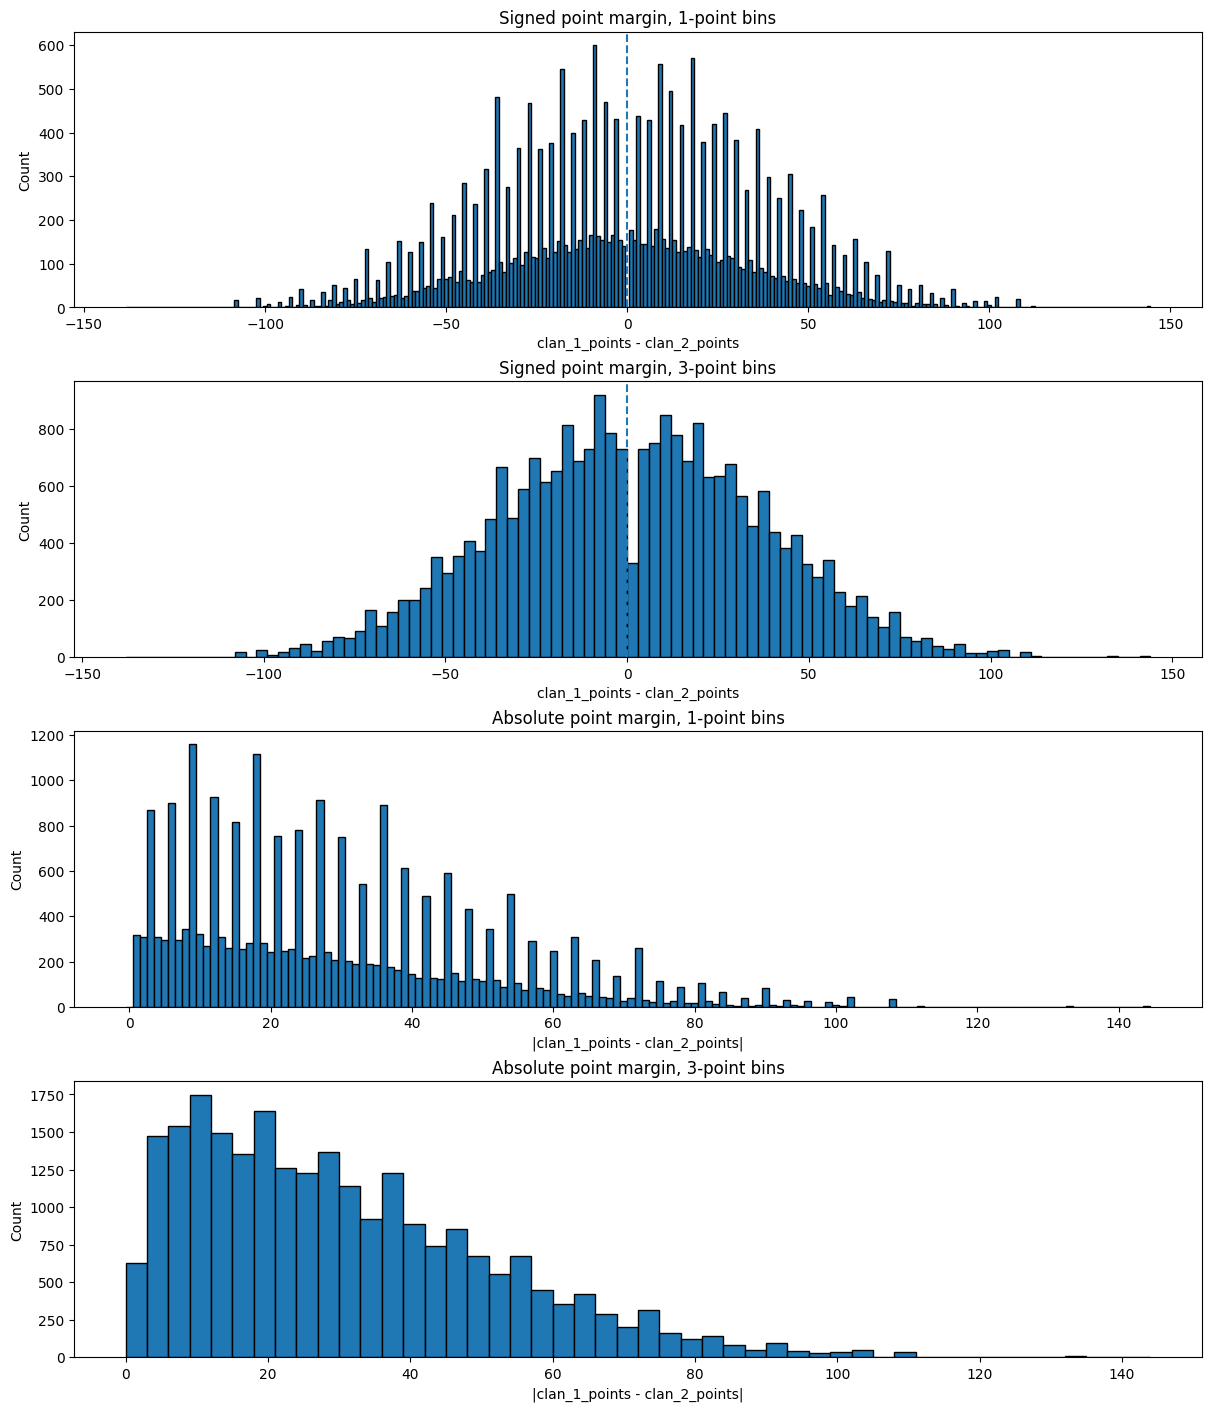

In [11]:
point_diff = matches["point_diff"]
abs_point_diff = matches["abs_point_diff"]

min_diff = int(np.floor(point_diff.min()))
max_diff = int(np.ceil(point_diff.max()))
max_abs_diff = int(np.ceil(abs_point_diff.max()))

signed_bins_1 = np.arange(min_diff - 0.5, max_diff + 1.5, 1)
signed_bins_3 = np.arange(
    3 * np.floor(min_diff / 3),
    3 * np.ceil(max_diff / 3) + 3,
    3,
)

abs_bins_1 = np.arange(-0.5, max_abs_diff + 1.5, 1)
abs_bins_3 = np.arange(0, 3 * np.ceil(max_abs_diff / 3) + 3, 3)

fig, axes = plt.subplots(4, 1, figsize=(12, 14), constrained_layout=True)

axes[0].hist(point_diff, bins=signed_bins_1, edgecolor="black")
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Signed point margin, 1-point bins")
axes[0].set_xlabel("clan_1_points - clan_2_points")
axes[0].set_ylabel("Count")

axes[1].hist(point_diff, bins=signed_bins_3, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Signed point margin, 3-point bins")
axes[1].set_xlabel("clan_1_points - clan_2_points")
axes[1].set_ylabel("Count")

axes[2].hist(abs_point_diff, bins=abs_bins_1, edgecolor="black")
axes[2].set_title("Absolute point margin, 1-point bins")
axes[2].set_xlabel("|clan_1_points - clan_2_points|")
axes[2].set_ylabel("Count")

axes[3].hist(abs_point_diff, bins=abs_bins_3, edgecolor="black")
axes[3].set_title("Absolute point margin, 3-point bins")
axes[3].set_xlabel("|clan_1_points - clan_2_points|")
axes[3].set_ylabel("Count")

plt.show()

## Margin buckets

The buckets below are automatic quintiles of the realised absolute margin. They are useful for diagnostics such as "are decisive matches easier to predict?" without hand-picking boundaries.



In [12]:
def add_margin_bucket(df, margin_col="abs_point_diff", q=5):
    df = df.copy()

    codes, edges = pd.qcut(
        df[margin_col],
        q=q,
        labels=False,
        retbins=True,
        duplicates="drop",
    )

    n_buckets = len(edges) - 1
    labels = ["Q1_closest"]
    labels += [f"Q{i}" for i in range(2, n_buckets)]
    labels += [f"Q{n_buckets}_largest"]

    bucket_values = [labels[int(code)] if pd.notna(code) else np.nan for code in codes]
    df["margin_bucket"] = pd.Categorical(bucket_values, categories=labels, ordered=True)

    return df, edges


matches, margin_edges = add_margin_bucket(matches, margin_col="abs_point_diff", q=5)

print("Bucket edges:", np.round(margin_edges, 3))

Bucket edges: [  1.  10.  20.  31.  47. 144.]


,margin_bucket,n_matches,share,mean_abs_point_diff,median_abs_point_diff,min_abs_point_diff,max_abs_point_diff
0,Q1_closest,5117,0.210680,5.882158,6.0,1,10
1,Q2,4759,0.195940,15.371296,15.0,11,20
2,Q3,4799,0.197587,25.734528,26.0,21,31
3,Q4,4817,0.198328,38.799460,39.0,32,47
4,Q5_largest,4796,0.197464,63.067556,60.0,48,144


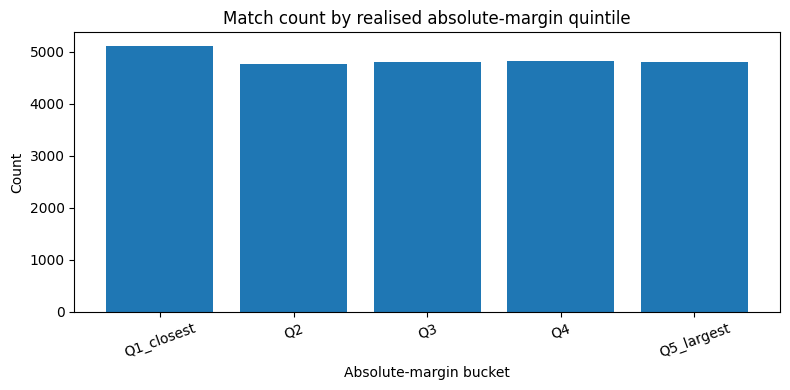

In [13]:
bucket_summary = (
    matches.groupby("margin_bucket", observed=False)
    .agg(
        n_matches=("point_diff", "size"),
        share=("point_diff", lambda x: len(x) / len(matches)),
        mean_abs_point_diff=("abs_point_diff", "mean"),
        median_abs_point_diff=("abs_point_diff", "median"),
        min_abs_point_diff=("abs_point_diff", "min"),
        max_abs_point_diff=("abs_point_diff", "max"),
    )
    .reset_index()
)

display(bucket_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(bucket_summary["margin_bucket"].astype(str), bucket_summary["n_matches"])
ax.set_title("Match count by realised absolute-margin quintile")
ax.set_xlabel("Absolute-margin bucket")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()